### Theoretical Comparative Study: $AlN:Mn$ vs $GaN:Mn$ vs $GaSb:Mn$

Three diluted magnetic semiconductors (DMS) are compared. A fixed doping concentration of $x=5\%$ is assumed for the magnetization and specific heat plots.

| Material | Structure | Lattice Parameters ($\text{\AA}$) | Cell Volume | $J$ (meV) |
| :---: | :---: | :---: | :---: | :---: |
| AlN:Mn | Wurtzite | $a=3.11, c=4.98$ | $\frac{\sqrt{3}}{2}a^2c$ | 18.0 |
| GaN:Mn | Wurtzite | $a=3.19, c=5.18$ | $\frac{\sqrt{3}}{2}a^2c$ | 18.0 |
| GaSb:Mn | Zinc-blende | $a=6.09$ | $a^3$ | 12.0 |

**Note:** Structural and magnetic parameters used. A spin of $S=5/2$ is assumed for all cases.

### **Simulation**

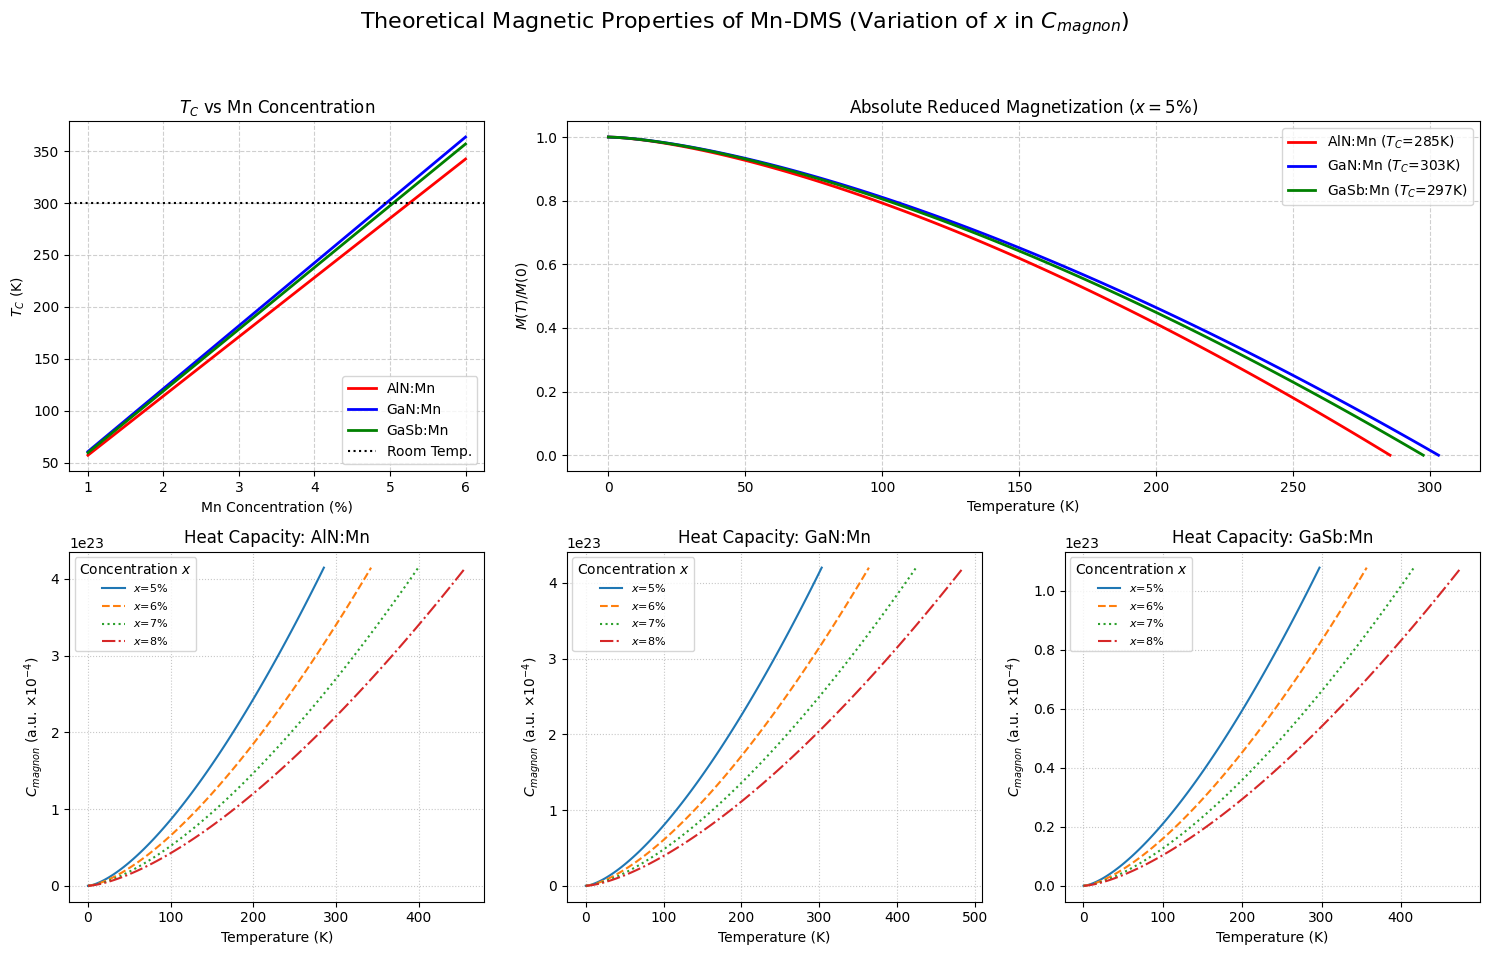

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import os

# ==========================================
# 1. CLASS AND PARAMETER DEFINITIONS
# ==========================================
kB = 0.08625      # Boltzmann constant (meV/K)
integral_factor = 0.0587

class Material:
    def __init__(self, name, structure, a, c, J, n, color, style='-'):
        self.name = name
        self.J = J # Exchange constant (meV)
        self.S = 2.5 # Spin 5/2 (Mn2+)
        self.n = n # Carrier density (m^-3)
        self.color = color
        self.style = style

        # Conversion to meters
        a_m = a * 1e-10

        # Unit Cell Volume Calculation (V_cell)
        if structure == 'wurtzite':
            c_m = c * 1e-10
            self.V_cell = (math.sqrt(3)/2) * (a_m**2) * c_m
            self.a_eff = a_m
        elif structure == 'zincblende':
            self.V_cell = a_m**3
            self.a_eff = a_m

    def calc_Tc(self, x):
        # T_c proportional to x * J * (spin_density)^(2/3)
        Term1 = x * (2 * self.J * self.S) / kB
        Term2 = ((self.n * self.S * self.V_cell) / integral_factor)**(2/3)
        return Term1 * Term2

    def calc_Cv(self, T, x):
        # Heat Capacity: C_magnon proportional to T^(3/2) / (x * J * S * a^2)^(3/2)
        constant = 0.113
        denom = (2 * self.J * x * self.S * self.a_eff**2)**1.5
        numerator = (kB**2.5) * (T**1.5)
        return (constant * numerator) / denom * 1e-4


# MATERIAL OBJECTS CREATION (Same order for axes)
mats = [
    Material("AlN:Mn", "wurtzite", a=3.11, c=4.98, J=18.0, n=7.2e27, color="red"),
    Material("GaN:Mn", "wurtzite", a=3.19, c=5.18, J=18.0, n=7.2e27, color="blue"),
    Material("GaSb:Mn", "zincblende", a=6.09, c=None, J=12.0, n=2.6e27, color="green")
]

# Concentration range for Cv plots
x_cv_range = [0.05, 0.06, 0.07, 0.08]
x_range_Tc = np.linspace(0.01, 0.06, 100) # Full range for plot 1
x_sim_M = 0.05 # Base concentration for Magnetization

# ==========================================
# 2. INDIVIDUAL PLOTTING AND SAVING (07 to 11)
# ==========================================
figures_dir = os.path.join('..', 'figures')
os.makedirs(figures_dir, exist_ok=True)

# --- FIGURE 07: Tc vs Concentration (x) ---
fig7, ax7 = plt.subplots(figsize=(6, 5))
for mat in mats:
    Tc_vals = mat.calc_Tc(x_range_Tc)
    ax7.plot(x_range_Tc*100, Tc_vals, color=mat.color, linewidth=2, label=mat.name)

ax7.set_title(r'$T_C$ vs Mn Concentration')
ax7.set_xlabel('Mn Concentration (%)')
ax7.set_ylabel(r'$T_C$ (K)')
ax7.grid(True, linestyle='--', alpha=0.6)
ax7.axhline(y=300, color='k', linestyle=':', label='Room Temp.')
ax7.legend()
fig7.tight_layout()
fig7.savefig(os.path.join(figures_dir, '07_Tc_vs_Mn_Concentration.png'), dpi=300, bbox_inches='tight')
plt.close(fig7) # Cierra la figura para no saturar la salida del notebook

# --- FIGURE 08: Reduced Magnetization (x=5%) ---
fig8, ax8 = plt.subplots(figsize=(6, 5))
for mat in mats:
    Tc_sim = mat.calc_Tc(x_sim_M)
    T_axis = np.linspace(0, Tc_sim, 100)
    M_vals = 1 - (T_axis / Tc_sim)**1.5
    ax8.plot(T_axis, M_vals, color=mat.color, linewidth=2, label=f"{mat.name} ($T_C$={Tc_sim:.0f}K)")

ax8.set_title(r'Absolute Reduced Magnetization ($x=5\%$)')
ax8.set_xlabel('Temperature (K)')
ax8.set_ylabel(r'$M(T)/M(0)$')
ax8.grid(True, linestyle='--', alpha=0.6)
ax8.legend()
fig8.tight_layout()
fig8.savefig(os.path.join(figures_dir, '08_Reduced_Magnetization.png'), dpi=300, bbox_inches='tight')
plt.close(fig8)

# --- FIGURES 09, 10, 11: Heat Capacity (Individual) ---
styles = ['-', '--', ':', '-.']
colors_cv = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for i, mat in enumerate(mats):
    fig_cv, ax_cv = plt.subplots(figsize=(6, 5))
    for j, x_val in enumerate(x_cv_range):
        Tc_x = mat.calc_Tc(x_val)
        T_axis_x = np.linspace(0.1, Tc_x, 100)
        Cv_vals = mat.calc_Cv(T_axis_x, x_val)
        ax_cv.plot(T_axis_x, Cv_vals, color=colors_cv[j], linestyle=styles[j], linewidth=1.5, label=f'$x$={x_val*100:.0f}%')

    ax_cv.set_title(f'Heat Capacity: {mat.name}')
    ax_cv.set_xlabel('Temperature (K)')
    ax_cv.set_ylabel(r'$C_{magnon}$ (a.u. $\times 10^{-4}$)')
    ax_cv.grid(True, linestyle=':', alpha=0.7)
    ax_cv.legend(title=r'Concentration $x$', fontsize=8)
    fig_cv.tight_layout()
    
    fig_num = 9 + i
    # Reemplaza los dos puntos ":" por un guión bajo "_" para evitar problemas en el nombre del archivo
    safe_name = mat.name.replace(":", "_")
    fig_cv.savefig(os.path.join(figures_dir, f'{fig_num:02d}_Heat_Capacity_{safe_name}.png'), dpi=300, bbox_inches='tight')
    plt.close(fig_cv)

# ==========================================
# 3. COMBINED DASHBOARD & FIGURE 12
# ==========================================
fig_dash = plt.figure(figsize=(15, 10))
gs = fig_dash.add_gridspec(2, 3)

ax1 = fig_dash.add_subplot(gs[0, 0]) # Tc vs x
ax2 = fig_dash.add_subplot(gs[0, 1:]) # Magnetization vs T
ax3 = fig_dash.add_subplot(gs[1, 0]) # Cv AlN
ax4 = fig_dash.add_subplot(gs[1, 1]) # Cv GaN
ax5 = fig_dash.add_subplot(gs[1, 2]) # Cv GaSb
axes_cv = [ax3, ax4, ax5]

# --- PLOT 1: Tc vs Concentration (x) ---
for mat in mats:
    Tc_vals = mat.calc_Tc(x_range_Tc)
    ax1.plot(x_range_Tc*100, Tc_vals, color=mat.color, linewidth=2, label=mat.name)

ax1.set_title(r'$T_C$ vs Mn Concentration')
ax1.set_xlabel('Mn Concentration (%)')
ax1.set_ylabel(r'$T_C$ (K)')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.axhline(y=300, color='k', linestyle=':', label='Room Temp.')
ax1.legend()

# --- PLOT 2: Reduced Magnetization ---
for mat in mats:
    Tc_sim = mat.calc_Tc(x_sim_M)
    T_axis = np.linspace(0, Tc_sim, 100)
    M_vals = 1 - (T_axis / Tc_sim)**1.5
    ax2.plot(T_axis, M_vals, color=mat.color, linewidth=2, label=f"{mat.name} ($T_C$={Tc_sim:.0f}K)")

ax2.set_title(r'Absolute Reduced Magnetization ($x=5\%$)')
ax2.set_xlabel('Temperature (K)')
ax2.set_ylabel(r'$M(T)/M(0)$')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

# --- PLOTS 3, 4, 5: Heat Capacity ---
for i, mat in enumerate(mats):
    ax = axes_cv[i]
    for j, x_val in enumerate(x_cv_range):
        Tc_x = mat.calc_Tc(x_val)
        T_axis_x = np.linspace(0.1, Tc_x, 100)
        Cv_vals = mat.calc_Cv(T_axis_x, x_val)
        ax.plot(T_axis_x, Cv_vals, color=colors_cv[j], linestyle=styles[j], linewidth=1.5, label=f'$x$={x_val*100:.0f}%')

    ax.set_title(f'Heat Capacity: {mat.name}')
    ax.set_xlabel('Temperature (K)')
    ax.set_ylabel(r'$C_{magnon}$ (a.u. $\times 10^{-4}$)')
    ax.grid(True, linestyle=':', alpha=0.7)
    ax.legend(title=r'Concentration $x$', fontsize=8)

fig_dash.suptitle(r'Theoretical Magnetic Properties of Mn-DMS (Variation of $x$ in $C_{magnon}$)', fontsize=16)
fig_dash.tight_layout(rect=[0, 0.03, 1, 0.95])

# Guardar el dashboard completo
fig_dash.savefig(os.path.join(figures_dir, '12_Combined_Dashboard.png'), dpi=300, bbox_inches='tight')

# Mostrar únicamente el dashboard en la salida de la celda de Jupyter
plt.show()